# 04 — Persistence, replay, streaming, and channel metrics

**Purpose.** Treat a realization as data: save it with checksums and provenance,
load it into another backend, replay it through the model interface, stream links,
and compute diagnostic metrics. All files live in a temporary directory.

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython import get_ipython

get_ipython().run_line_magic("matplotlib", "inline")


def find_repo_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else start
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "configs").is_dir():
            return candidate
    raise RuntimeError("Run this notebook from a Channel Dataset repository checkout")


def as_numpy(value):
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().numpy()
    return np.asarray(value)


ROOT = find_repo_root()
SOURCE_DIRECTORY = str(ROOT / "src")
if SOURCE_DIRECTORY not in sys.path:
    sys.path.insert(0, SOURCE_DIRECTORY)

from channel_dataset.core import ExecutionContext

execution = ExecutionContext("torch", "double", "cpu")
backend = execution.array_backend
print(f"Repository: {ROOT.name} | backend={execution.backend} | precision={execution.precision}")

Repository: Channel_Dataset | backend=torch | precision=double


## 1. Generate a multi-batch TDL realization

In [3]:
from channel_dataset.channels.wireless import ChannelSamplingRequest
from channel_dataset.channels.wireless.tr38901 import register_tdl_model
from channel_dataset.channels.wireless.transforms import cir_to_ofdm, subcarrier_frequencies
from channel_dataset.config import load_config
from channel_dataset.registry import ModelRegistry

envelope = load_config(ROOT / "configs/wireless/example_tdl.yaml")
registry = ModelRegistry()
register_tdl_model(registry)
model = registry.create(envelope)
request = ChannelSamplingRequest(3, 4, 30_720.0, execution, execution.random_stream(4401), "dataset")
cir = model.realize(request)
response = cir_to_ofdm(cir, subcarrier_frequencies(32, 15_000.0, execution))
print("source CIR:", cir.shape, "digest:", cir.metadata.config_digest[:16] + "…")

source CIR: (3, 1, 1, 1, 1, 24, 4) digest: 6526e05333ebc77d…


## 2. Save, cross-load into NumPy, and replay

In [4]:
from tempfile import TemporaryDirectory

from channel_dataset.channels.wireless import ReplayChannel, load_cir, save_cir
from channel_dataset.config import ConfigEnvelope

with TemporaryDirectory() as temporary_directory:
    destination = save_cir(Path(temporary_directory) / "tdl-cir", cir, chunk_size=2)
    numpy_execution = ExecutionContext("numpy", "double", "cpu")
    loaded = load_cir(destination, numpy_execution)

numpy_request = ChannelSamplingRequest(
    3, 4, 30_720.0, numpy_execution, numpy_execution.random_stream(4401), "dataset"
)
replayed = ReplayChannel((loaded,)).realize(numpy_request)
reconstructed = ConfigEnvelope.from_realization_metadata(replayed.metadata)

assert replayed.shape == cir.shape
assert replayed.metadata.config_digest == cir.metadata.config_digest
assert np.array_equal(replayed.coefficients, as_numpy(cir.coefficients))
assert reconstructed.model_digest == envelope.model_digest

print("loaded backend:", replayed.metadata.backend)
print("cross-backend coefficient equality: exact")
print("reconstructed model:", f"{reconstructed.family}/{reconstructed.name}")

loaded backend: numpy
cross-backend coefficient equality: exact
reconstructed model: wireless/tdl


## 3. Stream and deterministically shuffle individual links

In [5]:
from channel_dataset.channels.wireless import StreamingCIRDataset, shuffle_stream

dataset = StreamingCIRDataset(lambda index: loaded.select_link(index, 0, 0), length=3)
first = list(shuffle_stream(dataset, buffer_size=2, random_stream=numpy_execution.random_stream(4402)))
second = list(shuffle_stream(dataset, buffer_size=2, random_stream=numpy_execution.random_stream(4402)))
first_ids = [item.metadata.request_id for item in first]

assert len(first) == 3
assert all(np.array_equal(a.coefficients, b.coefficients) for a, b in zip(first, second, strict=True))
assert all(item.shape[:2] == (1, 1) for item in first)
print("deterministic shuffled batch fingerprints:", [round(float(np.abs(item.coefficients).sum()), 4) for item in first])

deterministic shuffled batch fingerprints: [15.2012, 16.4727, 18.8631]


## 4. Compute propagation and MIMO metrics

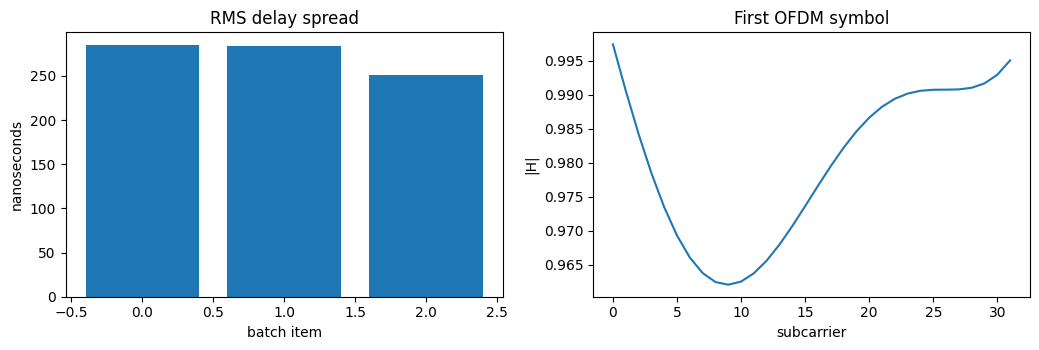

singular-value tensor: (3, 1, 1, 4, 32, 1)
frequency selectivity: [0.0241 0.1384 0.2807]


In [6]:
from channel_dataset.channels.wireless import (
    frequency_selectivity,
    mimo_singular_values,
    rms_delay_spread,
)

delay_spread = rms_delay_spread(cir)
selectivity = frequency_selectivity(response)
singular_values = mimo_singular_values(response)

assert torch.all(delay_spread > 0.0)
assert torch.all(selectivity >= 0.0)
assert torch.all(singular_values >= 0.0)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
axes[0].bar(np.arange(3), as_numpy(delay_spread[:, 0, 0]) * 1e9)
axes[0].set(title="RMS delay spread", xlabel="batch item", ylabel="nanoseconds")
axes[1].plot(as_numpy(torch.abs(response.coefficients[0, 0, 0, 0, 0, 0])))
axes[1].set(title="First OFDM symbol", xlabel="subcarrier", ylabel="|H|")
fig.tight_layout()
plt.show()
print("singular-value tensor:", tuple(singular_values.shape))
print("frequency selectivity:", np.round(as_numpy(selectivity[:, 0, 0]), 4))

## Manual check and next experiments

- Inspect `manifest.json` inside a non-temporary save to see chunk checksums and metadata.
- Corrupt a copied chunk and confirm loading fails rather than silently accepting it.
- Set `repeat=True` on `StreamingCIRDataset` or `ReplayChannel` for controlled loops.
- Compare delay spread and frequency selectivity across TDL profiles.